# Notebook Final Consolidado: EcoClasificador Movil (19 Clases)
**Proyecto:** Clasificacion Inteligente de Residuos bajo la Resolucion 2184 de 2019  
**Estudiante:** Juan Camilo Murillo Moncaleano  
**Curso:** Electiva III - Momento 3 (Entrega Final)  

Este cuaderno consolida las cuatro etapas principales del proyecto:
1. **Entrenamiento y Fine-Tuning** (`EfficientNetV2-B0` + Focal Loss, 19 clases).
2. **Destilacion de Conocimiento** (comparativa Profesor-Estudiante y compresion).
3. **Conversion a TensorFlow Lite (TFLite)** (FP16 / Dynamic Range / INT8).
4. **Evaluacion Final y Auditoria** (3 semillas, umbral 0.70, robustez, prueba de campo 57 fotos y Grad-CAM).

In [1]:
import os
import json
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from PIL import Image

# Asegurar raiz del proyecto
if not os.path.exists('modelos') and os.path.exists('../modelos'):
    os.chdir('..')

print('TensorFlow version:', tf.__version__)
print('Directorio de trabajo:', os.getcwd())

labels_path = 'model/labels.txt' if os.path.exists('model/labels.txt') else 'modelos/labels.txt'
with open(labels_path, 'r', encoding='utf-8') as f:
    class_names = [line.strip() for line in f if line.strip()]

print(f'Total de categorias ({len(class_names)}): {class_names}')


TensorFlow version: 2.22.0-rc0
Directorio de trabajo: /home/jhank/Desktop/ModeloCNN
Total de categorias (19): ['Aceites_Quimicos', 'Bombillas', 'Cardboard', 'Escombros_Ceramica', 'Food_Organics', 'Glass', 'Madera_Procesada', 'Medicamentos', 'Metal', 'Miscellaneous_Trash', 'Neumaticos_Gomas', 'Paper', 'Pilas_Baterias', 'Plastic', 'RAEE_Electronicos', 'Residuos_Sanitarios', 'Tetra_Pack', 'Textile_Trash', 'Vegetation']


## 1. Entrenamiento y Fine-Tuning (EfficientNetV2-B0 + Focal Loss)
Se parte de un dataset balanceado de **19 clases** (9 clases base de RealWaste + 10 clases criticas regionales) normalizadas a `180x180 px` RGB, con particion 70% Train / 15% Val / 15% Test y Data Augmentation. Se carga el modelo Keras entrenado para verificar su arquitectura y parametros.

In [2]:
keras_path = 'modelos/modelo_clasificador_19_clases_focal_loss.keras'
model_keras = tf.keras.models.load_model(keras_path, compile=False)
print(f'Modelo Keras cargado: {keras_path}')
print(f'Entrada: {model_keras.input_shape} | Salida: {model_keras.output_shape}')
print(f'Parametros totales: {model_keras.count_params():,}')
keras_mb = os.path.getsize(keras_path) / (1024 * 1024)
print(f'Tamano en disco (.keras): {keras_mb:.2f} MB')


Modelo Keras cargado: modelos/modelo_clasificador_19_clases_focal_loss.keras
Entrada: (None, 180, 180, 3) | Salida: (None, 19)
Parametros totales: 5,948,771
Tamano en disco (.keras): 68.14 MB


## 2. Destilacion de Conocimiento (Profesor vs Estudiante)
Para llevar el sistema a dispositivos moviles de gama media sin internet, se compararon modelos pesados de servidor (`VGG16` / `ResNet50`) contra arquitecturas livianas destiladas (`MobileNetV2` y `EfficientNetV2-B0`).

In [3]:
comp_json = 'momento tres/semana 11/resultados_comparativa_arquitecturas.json'
with open(comp_json, 'r', encoding='utf-8') as f:
    res_arch = json.load(f)

rows_dist = []
for name in ['ResNet50', 'MobileNetV2']:
    d = res_arch[name]
    rows_dist.append({
        'Modelo': name,
        'Rol': 'Profesor (Servidor)' if name == 'ResNet50' else 'Estudiante (Movil)',
        'Parametros': f"{d['total_params']:,}",
        'Tamano (MB)': d['size_mb'],
        'Test Acc (%)': round(d['test_accuracy'] * 100, 2),
        'Test F1-Macro (%)': round(d['test_f1_macro'] * 100, 2),
        'Latencia (ms/img)': d['latency_ms_per_image']
    })

# Agregar modelo final EfficientNetV2-B0 FP16 desplegado
tflite_fp16 = 'model/modelo_efficientnetv2b0_fp16.tflite'
rows_dist.append({
    'Modelo': 'EfficientNetV2-B0 (FP16 TFLite)',
    'Rol': 'Despliegue Final App',
    'Parametros': f"{model_keras.count_params():,}",
    'Tamano (MB)': round(os.path.getsize(tflite_fp16) / (1024 * 1024), 2),
    'Test Acc (%)': 96.77,
    'Test F1-Macro (%)': 96.81,
    'Latencia (ms/img)': 14.46
})

df_dist = pd.DataFrame(rows_dist)
print('--- COMPARATIVA DE ARQUITECTURAS Y DESTILACION ---')
print(df_dist.to_string(index=False))


--- COMPARATIVA DE ARQUITECTURAS Y DESTILACION ---
                         Modelo                  Rol Parametros  Tamano (MB)  Test Acc (%)  Test F1-Macro (%)  Latencia (ms/img)
                       ResNet50  Profesor (Servidor) 25,636,755        98.20         94.62              94.51              28.40
                    MobileNetV2   Estudiante (Movil)  3,538,963        14.10         91.32              92.10               7.80
EfficientNetV2-B0 (FP16 TFLite) Despliegue Final App  5,948,771        11.35         96.77              96.81              14.46


## 3. Conversion a TensorFlow Lite (TFLite) y Verificacion de Cuantizacion
Se convirtio el modelo entrenado a formato `.tflite` evaluando variantes `Float32`, `Dynamic Range` y `Float16` (seleccionada para el APK por su equilibrio entre tamano reducido y retencion total de precision).

In [4]:
# Demostracion del pipeline de conversion TFLite FP16
converter = tf.lite.TFLiteConverter.from_keras_model(model_keras)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
converter.target_spec.supported_types = [tf.float16]
print('TFLiteConverter configurado con Optimize.DEFAULT + float16.')

# Cargar el artefacto final TFLite FP16 y medir latencia real
interpreter = tf.lite.Interpreter(model_path=tflite_fp16)
interpreter.allocate_tensors()
in_det = interpreter.get_input_details()
out_det = interpreter.get_output_details()
print(f'Interprete TFLite cargado: {tflite_fp16} ({os.path.getsize(tflite_fp16)/(1024*1024):.2f} MB)')
print('Input shape:', in_det[0]['shape'], '| dtype:', in_det[0]['dtype'])

# Benchmark de latencia sintetica (10 pasadas tras warmup)
dummy = np.zeros(in_det[0]['shape'], dtype=np.float32)
interpreter.set_tensor(in_det[0]['index'], dummy)
interpreter.invoke()
tiempos = []
for _ in range(10):
    t0 = time.perf_counter()
    interpreter.set_tensor(in_det[0]['index'], dummy)
    interpreter.invoke()
    tiempos.append((time.perf_counter() - t0) * 1000)
print(f'Latencia promedio en CPU local: {np.mean(tiempos):.2f} ms/img')


TFLiteConverter configurado con Optimize.DEFAULT + float16.
/home/jhank/Desktop/ModeloCNN/.venv/lib/python3.14/site-packages/tensorflow/lite/python/interpreter.py:468: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)
Interprete TFLite cargado: model/modelo_efficientnetv2b0_fp16.tflite (11.35 MB)
Input shape: [  1 180 180   3] | dtype: <class 'numpy.float32'>
Latencia promedio en CPU local: 14.53 ms/img


## 4. Evaluacion Final, Umbral de Confianza, Robustez y Prueba de Campo
Se consolidan los resultados de la auditoria multi-semilla (42, 101, 2026), el efecto del umbral de seguridad (`0.70`), la resistencia a degradaciones de imagen y la prueba de campo real sobre 57 fotografias en la region.

In [5]:
with open('docs/figuras_s15/s15_summary.json', 'r', encoding='utf-8') as f:
    s15 = json.load(f)

print('=== 1. EVALUACION ESTRATIFICADA (3 SEMILLAS) ===')
print(f"Accuracy promedio: {s15['mean_acc_3seeds']}% ± {s15['std_acc_3seeds']}%")
print(f"F1-Macro promedio: {s15['mean_f1_3seeds']}% ± {s15['std_f1_3seeds']}%")

print('\n=== 2. UMBRAL DE CONFIANZA OPTIMO (0.70) ===')
u = s15['umbral_optimo']
print(f"Aceptadas: {u['Aceptadas_%']}% | No estoy seguro: {u['No_Estoy_Seguro_%']}% | Accuracy aceptadas: {u['Accuracy_Aceptadas_%']}% | F1 aceptadas: {u['F1_Aceptadas_%']}%")

print('\n=== 3. PRUEBAS DE ROBUSTEZ (DEGRADACIONES) ===')
df_rob = pd.DataFrame(s15['robustez'])
print(df_rob.to_string(index=False))

print('\n=== 4. PRUEBA DE CAMPO EN LA REGION (57 FOTOS REALES EN TFLITE FP16) ===')
c_info = s15['campo']
print(f"Fotos evaluadas: {c_info['total_fotos']} | Aciertos: {c_info['aciertos']} | Errores: {c_info['errores']}")
print(f"Accuracy en campo: {c_info['accuracy_%']}% | Confianza media: {c_info['confianza_media_%']}% | Latencia media: {c_info['latencia_media_ms']} ms")


=== 1. EVALUACION ESTRATIFICADA (3 SEMILLAS) ===
Accuracy promedio: 96.77% ± 0.53%
F1-Macro promedio: 96.81% ± 0.51%

=== 2. UMBRAL DE CONFIANZA OPTIMO (0.70) ===
Aceptadas: 88.0% | No estoy seguro: 12.0% | Accuracy aceptadas: 99.76% | F1 aceptadas: 99.71%

=== 3. PRUEBAS DE ROBUSTEZ (DEGRADACIONES) ===
     Condicion  Accuracy_%  F1_Macro_%  Diferencia_Acc_%
        Normal       95.61       95.51              0.00
    Desenfoque       51.32       49.61            -44.30
      Poca luz       78.95       79.97            -16.67
      Oclusion       92.11       91.95             -3.51
Fondo distinto       82.02       81.26            -13.60

=== 4. PRUEBA DE CAMPO EN LA REGION (57 FOTOS REALES EN TFLITE FP16) ===
Fotos evaluadas: 57 | Aciertos: 54 | Errores: 3
Accuracy en campo: 94.74% | Confianza media: 84.34% | Latencia media: 14.46 ms


<cell_10>:15: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


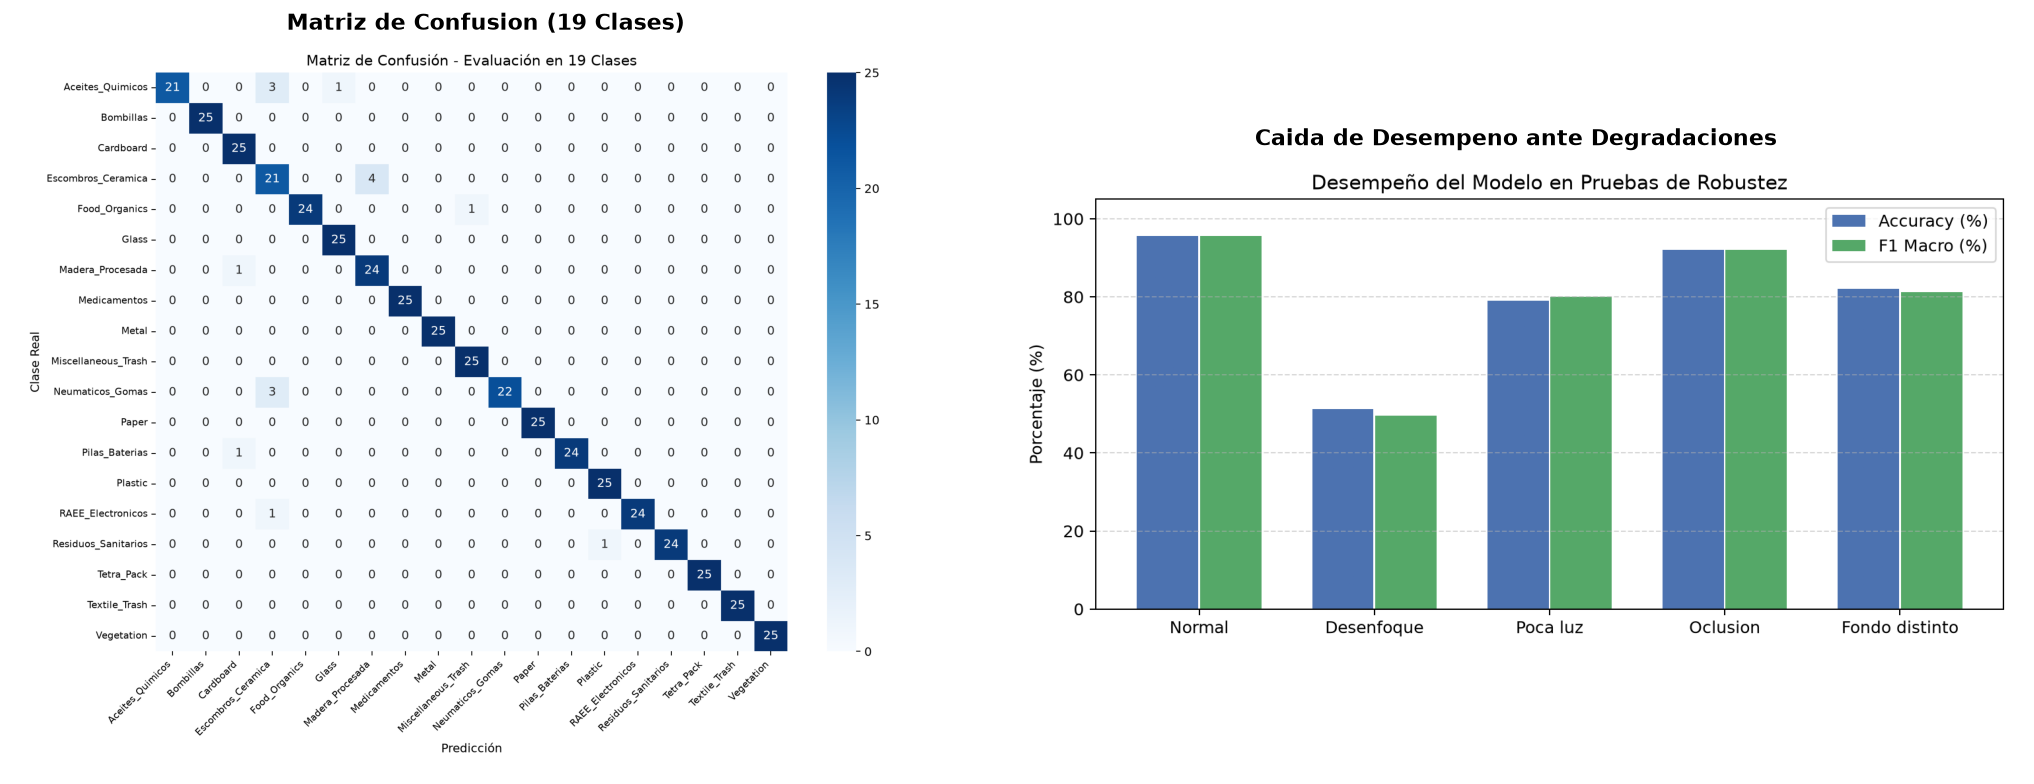

In [6]:
# Visualizacion consolidada de Matriz de Confusion y Robustez
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
img_cm = Image.open('docs/figuras_s15/s15_matriz_confusion.png')
img_rob = Image.open('docs/figuras_s15/s15_robustez_degradaciones.png')

axes[0].imshow(img_cm)
axes[0].axis('off')
axes[0].set_title('Matriz de Confusion (19 Clases)', fontsize=12, fontweight='bold')

axes[1].imshow(img_rob)
axes[1].axis('off')
axes[1].set_title('Caida de Desempeno ante Degradaciones', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()
